# Klasifikasi Multikelas: Maternal Health Risk

Dataset Maternal Health Risk mengumpulkan data parameter kesehatan vital dari ibu hamil yang diperoleh dari berbagai rumah sakit dan klinik pedesaan di Bangladesh. Dataset ini bersumber dari UCI Machine Learning Repository.

- Nama dataset: Maternal Health Risk
- Sumber data: UCI Machine Learning Repository (ID: 863)
- Link dataset: https://archive.ics.uci.edu/dataset/863/maternal+health+risk
- Dimensi data: 1.014 baris dan 7 kolom (6 fitur klinis dan 1 kolom target)
- Variabel target: Kolom `RiskLevel` dengan 3 tingkatan risiko maternal: low risk, mid risk, dan high risk

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

maternal = fetch_ucirepo(id=863)
X = maternal.data.features
y = maternal.data.targets
df = pd.concat([X, y], axis=1)

print("Shape data:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)

Shape data: (1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk



Tipe data:
Age              int64
SystolicBP       int64
DiastolicBP      int64
BS             float64
BodyTemp       float64
HeartRate        int64
RiskLevel          str
dtype: object


Jumlah kelas: 3 => multikelas: True

Distribusi kelas:
RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64


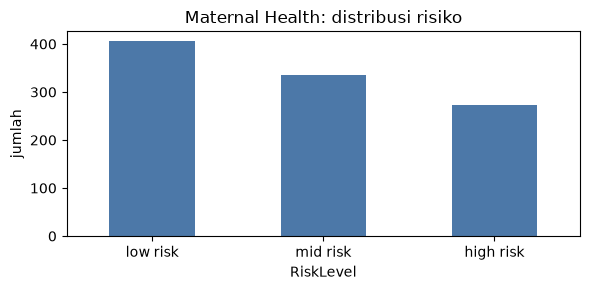

In [2]:
import matplotlib.pyplot as plt

def plot_dist(y, title, rot=0):
    ax = pd.Series(y).value_counts().plot(kind="bar", figsize=(6, 3), color="#4C78A8")
    ax.set_title(title)
    ax.set_ylabel("jumlah")
    plt.xticks(rotation=rot)
    plt.tight_layout()
    plt.show()

target_col = "RiskLevel"

print("Jumlah kelas:", df[target_col].nunique(), "=> multikelas:", df[target_col].nunique() > 2)
print("\nDistribusi kelas:")
print(df[target_col].value_counts())
plot_dist(df[target_col], "Maternal Health: distribusi risiko")

In [3]:
assert df[target_col].nunique() == 3, f"Nilai unik harus 3, didapat: {df[target_col].nunique()}"
assert df[target_col].nunique() > 2, "Harus lebih dari 2 kelas untuk multikelas"
assert set(df[target_col].unique()) == {"low risk", "mid risk", "high risk"}, "Label kategori target tidak sesuai"
assert df[target_col].isnull().sum() == 0, "Target mengandung nilai null"
assert df.shape == (1014, 7), f"Bentuk dataframe tidak sesuai: {df.shape}"

print("Semua verifikasi lolos.")

Semua verifikasi lolos.


## Kesimpulan

Dataset Maternal Health Risk merupakan klasifikasi multikelas dengan 3 kelas pada kolom target `RiskLevel`:
- low risk (406 pasien)
- mid risk (336 pasien)
- high risk (272 pasien)

Setiap pasien hamil hanya memiliki satu penilaian risiko tunggal.